In [1]:
# coding: utf-8

#MST algorithm

#usage

# Alter value of 'l1,l2' to set Galactic longitude range
# Alter value of 'my_dL', 'my_dV' to set critical separation of two connected vertex
# If nodes have no velocity information, please set 'my_dV' to -1.
# Give the path of your table containing Galactic longitude, latitude (and velocity) to 'filename'.

my_dL = .1
my_dV = 1

#csv_filename = 'mopra_higal_lbv_results.csv'
csv_filename = 'mopra_higal_lbv_results_enhanced.csv' # Run the whole thing with this if you want to colour-code

import numpy as np
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
from matplotlib.cbook import flatten
import pickle
from matplotlib.ticker import MultipleLocator, FuncFormatter
import os
from astropy import units as u
from astropy.io import fits
import pandas as pd

In [2]:
## Function 1, run this with no fear

#def get_lbv(l1=253.35, l2=253.8, b1 = -0.3, b2 = -0.1, my_dV=my_dV):
#def get_lbv(l1=252.5, l2=255, my_dV=my_dV):
def get_lbv(l1, l2, b1, b2, my_dV=my_dV):
    
    fp = open(csv_filename) 
    l=[]
    b=[]
    v=[]
    for linea in fp.readlines():
        linea=linea.strip().split(",")[:]
        if my_dV == -1:
            v.append(0)
        else:
            try:
                v.append(float(linea[3]))
            except ValueError:
                continue
        l.append(float(linea[1]))
        b.append(float(linea[2])) 
    l = np.array(l)
    b = np.array(b)
    v = np.array(v)     
     
    # mask arrays
    # mask on vlsr
    mv = np.ma.masked_where(v>-999, v).mask
    # mask on l
    ml = np.ma.masked_where( (l>l1)&(l<l2), l).mask
    mb = np.ma.masked_where( (b>b1)&(b<b2), b).mask
    print(l, ml)
    mask = ml*mv*mb
    l = l[mask]
    b = b[mask]
    v = v[mask]
     
    # form 3d and 2d arrays, to be used to generate MST
    lbv = np.zeros( (len(l), 3) )
    lbv[:,0] = l
    lbv[:,1] = b
    lbv[:,2] = v
    lb = lbv[:,0:2]
 
    return lbv

In [3]:
## Function 2, run with no fear

def minimum_spanning_tree(X, v, copy_X=True, my_dL=my_dL):
    #X are edge weights of fully connected graph
    if copy_X:
        X = X.copy()
  
    if X.shape[0] != X.shape[1]:
        raise ValueError("X needs to be square matrix of edge weights")
    n_vertices = X.shape[0]
    spanning_edges = []
    break_point = []
      
    # initialize with node 0:                                                                                         
    visited_vertices = [0]                                                                                            
    num_visited = 0
    # exclude self connections:
    diag_indices = np.arange(n_vertices)
    X[diag_indices, diag_indices] = np.inf
      
    while num_visited != n_vertices:
        new_edge = np.argmin(X[visited_vertices], axis=None) 
        # 2d encoding of new_edge from flat, get correct indices
        new_edge = divmod(new_edge, n_vertices) 
        new_edge = [visited_vertices[new_edge[0]], new_edge[1]]
         
        # add edge to tree
        edge_length = np.min(X[visited_vertices])
        dv = abs(v[new_edge[1]] - v[new_edge[0]])
         
        # define conditions to accept edge
        separation = (edge_length < my_dL)
 
        if True:
            if separation:
                spanning_edges.append(new_edge)
            else:
                break_point.append(len(spanning_edges))
        visited_vertices.append(new_edge[1])
        # remove all edges inside current tree
        X[visited_vertices, new_edge[1]] = np.inf
        X[new_edge[1], visited_vertices] = np.inf                                                                     
        num_visited += 1
 
    # now we have a list of spanning_edges, break the list into individual branches
    # build up branch list
    b = break_point
    b = [0]+b # index of first edge element
    b = b+[-1] # index of last edge element
    branch_list = []
    for i in range(0,len(b)-1):
        branch = spanning_edges[ b[i]:b[i+1] ]
        if len(branch) > 4:
            branch_list.append(branch)
    return branch_list

In [4]:
## Function 3, run with no fear

def test_mst(l1, l2, b1, b2, my_dV=my_dV):
    lbv = get_lbv(l1=l1, l2=l2, b1=b1, b2=b2, my_dV=my_dV)
    l,b,v = lbv[:,0], lbv[:,1], lbv[:,2]
    P = lbv[:,0:2] # 2d position l,b
    plt.close('all') # close all figures
    plt.figure(figsize=(int(abs(l1-l2)*3), 3),dpi=800)
    
    if my_dV != -1:
        plt.scatter(P[:, 0], P[:, 1], s=5, c=v, cmap='cubehelix', alpha=.8)
        cb = plt.colorbar(pad=0.01)
        cb.set_label(label=r'$V_\mathrm{LSR} \,\, (\mathrm{km \, s^{-1}})$', fontsize='x-large')
        cb.ax.tick_params(labelsize='large')
    else:
        plt.scatter(P[:, 0], P[:, 1], s=5, c='tan', alpha=.8)
    plt.xlim(l2, l1)
    plt.xlabel('Galactic Longitude (deg)',fontsize='x-large')
    plt.ylabel('Galactic Latitude (deg)',fontsize='x-large')
    plt.grid()
    plt.tick_params(labelsize='small',grid_alpha=0.5,direction='in')
 
 
  
    X = squareform(pdist(P))
    max_length = np.percentile(pdist(P), 25) 
 
    # weight distance with velocity difference
    for i in range(0,X.shape[0]):
        for j in range(0,X.shape[0]):
            dv = abs(v[i] - v[j])
            if (dv > my_dV) & (X[i,j] < 1*my_dL):
                X[i,j] = X[i,j]*dv                 

    branch_list = minimum_spanning_tree(X,v)
    with open("branch_list.dat", 'wb') as f:
        pickle.dump(branch_list, f)
    with open("branch_list.dat", 'rb') as f:
        my_list = pickle.load(f)
 

    # per filament
    for branch in branch_list:
        if len(branch)>1: 
            branch = np.vstack(branch)
       # print ('plotting branch has # of clumps:', len(branch)+1)
        #print (branch)
 
        # all clumps in this filament
        clump_index = np.unique(np.array(branch))
        ci = clump_index
        l_wt = np.sum( l[ci] * v[ci] ) / np.sum(v[ci])
        b_wt = np.sum( b[ci] * v[ci] ) / np.sum(v[ci])
 
        for edge in branch:
            i, j = edge
            plt.plot([P[i, 0], P[j, 0]], [P[i, 1], P[j, 1]], c='k', lw=1, alpha=.6)
 
   # print ('len(branch_list)', len(branch_list))
 
    plt.tight_layout()

In [5]:
#l1, l2 = 252.5, 255
#l1, l2 = 253.35, 253.8
l1, l2 = 270, 280
lmin, lmax = l1, l2
#bmin, bmax = -1, 0.1
#bmin, bmax = -0.3, -0.1
bmin, bmax = -1, 0.1

[250.037552 250.10321  250.227356 ... 279.9599   279.972321 279.976166] [False False False ...  True  True  True]




In [6]:
## Outputs 2 files, commented out
## Run fearlessly

if __name__ == "__main__":

    test_mst(l1, l2, bmin, bmax)
    #test_mst(l1=253.35, l2=253.8, b1=-0.3, b2=-0.1)
    ax = plt.gca()
    ax.xaxis.set_major_locator( MultipleLocator(0.5) )
    ax.yaxis.set_major_locator( MultipleLocator(0.5) )
    plt.title(r'MST',fontsize='xx-large')
    plt.tight_layout()
    if not os.path.isdir('fig'):
        os.makedirs('fig')
   # plt.savefig('fig/demo_255.pdf')
   # plt.savefig('fig/demo_255.png')

In [7]:
#lbv=get_lbv(l1=253.35, l2=253.8, b1=-0.3, b2=-0.1,my_dV=my_dV)
lbv=get_lbv(l1, l2, bmin, bmax,my_dV=my_dV)
len(lbv)

[250.037552 250.10321  250.227356 ... 279.9599   279.972321 279.976166] [False False False ...  True  True  True]


643

In [8]:
lbv

array([[270.003174,  -0.768782,   4.65    ],
       [270.015106,  -0.786422,   4.69    ],
       [270.021423,  -0.748401,   5.92    ],
       ...,
       [279.9599  ,  -0.426497,  -1.33    ],
       [279.972321,  -0.539067,  35.24    ],
       [279.976166,  -0.408955,  -1.41    ]])

In [9]:
b=lbv[:,1]
b.max()

0.096291

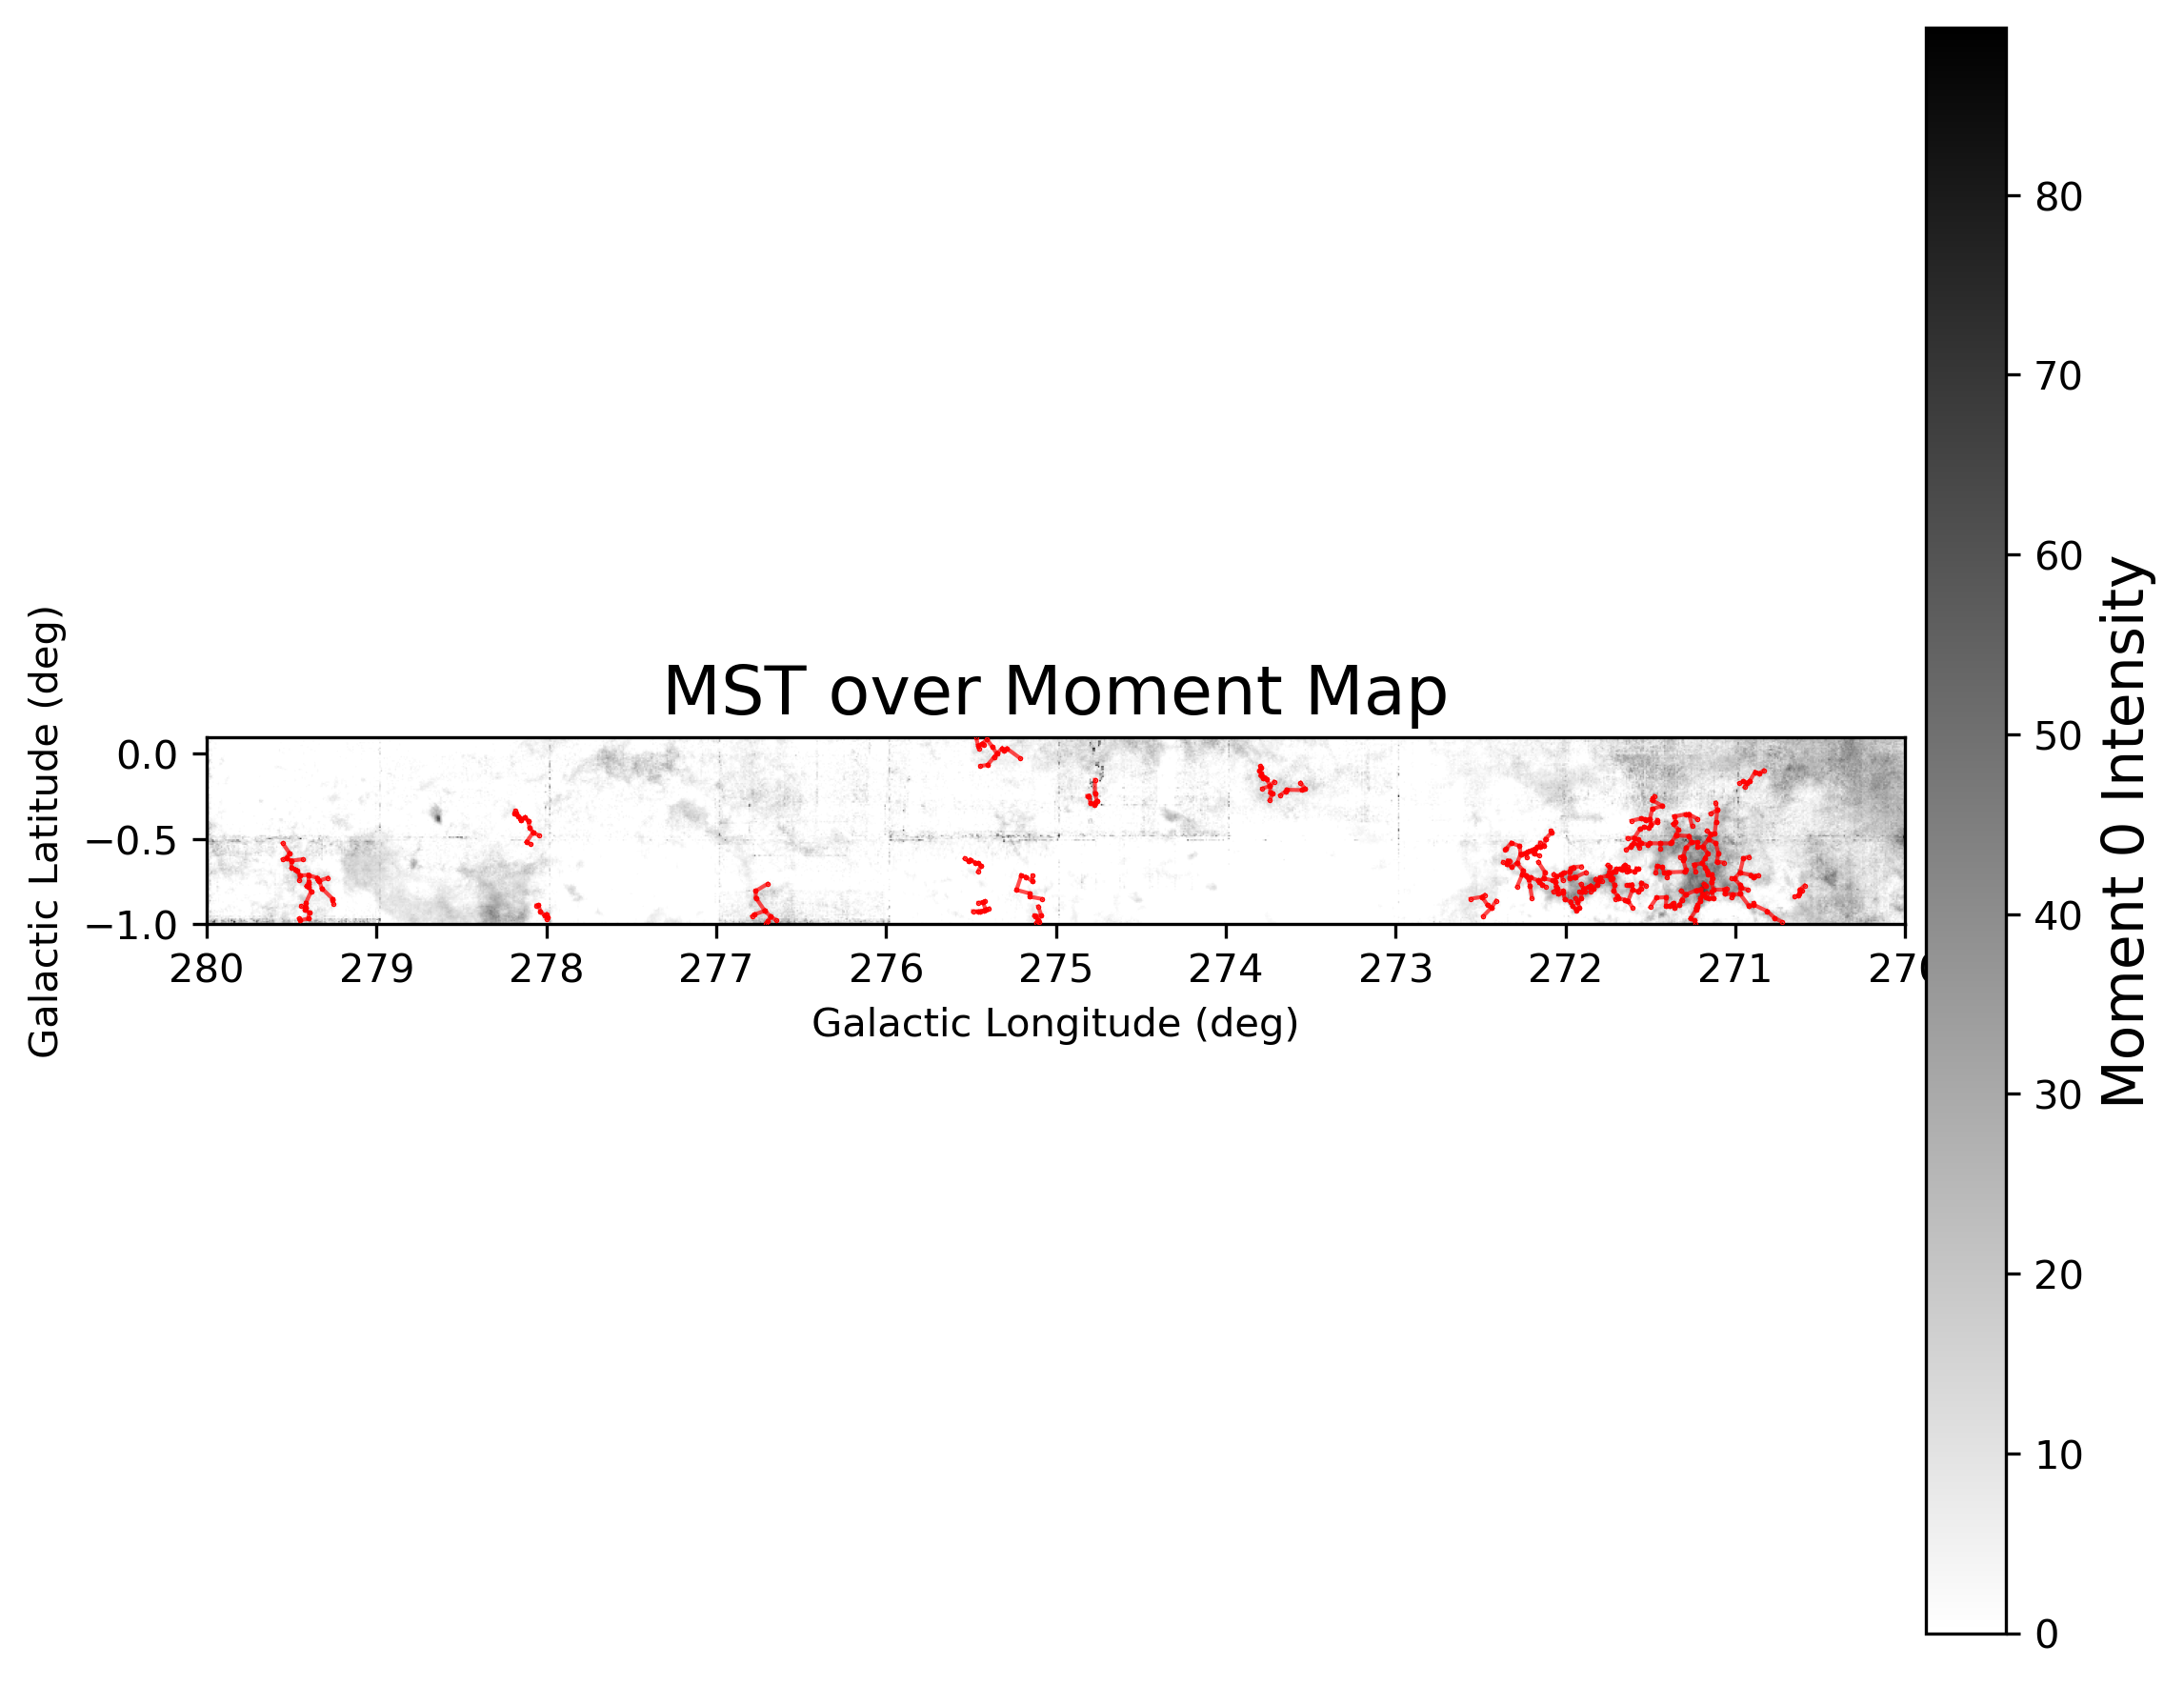

In [10]:
# Run fearlessly
# Succesful attempt at plotting the MST on top of the moment map. Deleted previous attempts

# Load the FITS moment map
#
#filename = "G250-260-12CO_giantcube_fullres_V25_V45_G252.50_G255.00_b-1.00_b0.10.st.mom0.fits" # Original region
#filename = 'G250-260-12CO_giantcube_fullres_V25_V45_G253.35_G253.80_b-0.30_b-0.10.st.mom0.fits' # Ring region
#filename = 'G250-260-12CO_giantcube_fullres_V0_V40_G250.00_G260.00_b-1.00_b0.10.st.mom0.fits' # Full 250-260
#filename = 'G260-270-12CO_giantcube_fullres_V-8_V23_G260.00_G270.00_b-1.00_b0.10.st.mom0.fits' # Full 260-270
filename = 'G270-280-12CO_giantcube_fullres_V-13_V14_G270.00_G280.00_b-1.00_b0.10.st.mom0.fits' # Full 270-280
file_path = "/Users/kyriakos.trakakis/Downloads/MST/Moments_MST/"
fits_file = file_path + filename
hdu = fits.open(fits_file)[0]
data = hdu.data
header = hdu.header

l1, l2 = lmin, lmax

# Plot the moment map
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
img=ax.imshow(data, origin="lower", cmap="gray_r", extent=[l2, l1, bmin, bmax]) # To remove the colourbar, remove img= and the next 2 lines
# cmap= gray_r for Michael

cbar = plt.colorbar(img, ax=ax, pad=0.01)  # pad adjusts spacing
cbar.set_label("Moment 0 Intensity", fontsize="x-large")  # Label for the colorbar

# Adjust axis limits and ticks
plt.xlim(l2, l1)
plt.ylim(bmin, bmax)
ax.xaxis.set_major_locator(MultipleLocator(1)) # set to 1 to display every 1 degree instead of 0.5
ax.yaxis.set_major_locator(MultipleLocator(0.5))
plt.xlabel("Galactic Longitude (deg)")
plt.ylabel("Galactic Latitude (deg)")
plt.title("MST over Moment Map", fontsize="xx-large")
plt.tight_layout()

# Load the branch_list from the MST analysis (assuming it's saved as 'branch_list.dat')
with open("branch_list.dat", 'rb') as f:
    branch_list = pickle.load(f)

# Initialize empty lists to store coordinates for plotting
l_vals = []  # Galactic longitude
b_vals = []  # Galactic latitude

# Loop through each branch in the branch_list and collect the coordinates
for branch in branch_list:
    for edge in branch:
        # Extract the indices (i, j) of the clumps
        i, j = edge
        
        # Get l, b coordinates for the two points from the lbv array (replace with actual data)
        l1, b1 = lbv[i, 0], lbv[i, 1]  # l, b values for clump i
        l2, b2 = lbv[j, 0], lbv[j, 1]  # l, b values for clump j

        # Append the coordinates to the lists
        l_vals.extend([l1, l2])
        b_vals.extend([b1, b2])

# Plot all the points as red points (no need for WCS transformation)
plt.scatter(l_vals, b_vals, c='r', s=0.1, zorder=5) # s is 5 for small files and 0.1 for big ones

# Now plot the edges (lines) by connecting the points
for branch in branch_list:
    for edge in branch:
        i, j = edge
        
        # Get l, b coordinates for the two points
        l1, b1 = lbv[i, 0], lbv[i, 1]  # l, b values for clump i
        l2, b2 = lbv[j, 0], lbv[j, 1]  # l, b values for clump j

        # Plot the MST edges (connect the points with a line)
        plt.plot([l1, l2], [b1, b2], c='r', lw=1, alpha=0.7)

# Show the final plot with MST overlaid on the moment map
plt.show()

# Starting attempt to colour-code nodes by parameters

In [11]:
# Gets l, b, v from the enhanced csv. color_col is:
# 4 for Dhc (redundant, all assumed near each other)
# 5 for Rgc ""
# 6 for Mass (Sol)
# 7 for gas2dust
# 8 for diameter (pc)
# 9 for Luminosity (Sol)
# 10 for L / M
# Run fearlessly

csv_filename_enhanced = 'mopra_higal_lbv_results_enhanced.csv'

def get_lbv_enhanced(lmin, lmax, bmin, bmax, my_dV=my_dV, color_col=10):
    """
    Returns:
        lbv        : (N, 3) array of l, b, v
        color_val  : (N,)   array used for colour coding
        df_all     : pandas DataFrame containing *all CSV columns*,
                     filtered to the same mask as lbv
    """

    # --- Load CSV into a dataframe (keeps all columns!) ---
    df = pd.read_csv(csv_filename_enhanced, header = None)
    df_columns = df.iloc[0]
    df = df[1:].reset_index(drop=True)

    # Extract columns used for lbv and colour
    l = df[1].astype(float).values
    b = df[2].astype(float).values
    if my_dV == -1:
        v = np.zeros(len(df))
    else:
        v = df[3].astype(float).values

    color_val = df[color_col].astype(float).values

    # --- Apply masks exactly as your original code ---
    mv = np.ma.masked_where(v > -999, v).mask
    ml = np.ma.masked_where((l > lmin) & (l < lmax), l).mask
    mb = np.ma.masked_where((b > bmin) & (b < bmax), b).mask
    mask = ml * mv * mb

    # --- Filter lbv and color ---
    l, b, v, color_val = l[mask], b[mask], v[mask], color_val[mask]

    lbv = np.zeros((len(l), 3))
    lbv[:, 0] = l
    lbv[:, 1] = b
    lbv[:, 2] = v

    # --- Filter full dataframe using the same mask ---
    df_all = df.iloc[mask].reset_index(drop=True)
    df_all.columns = df_columns  

    return lbv, color_val, df_all

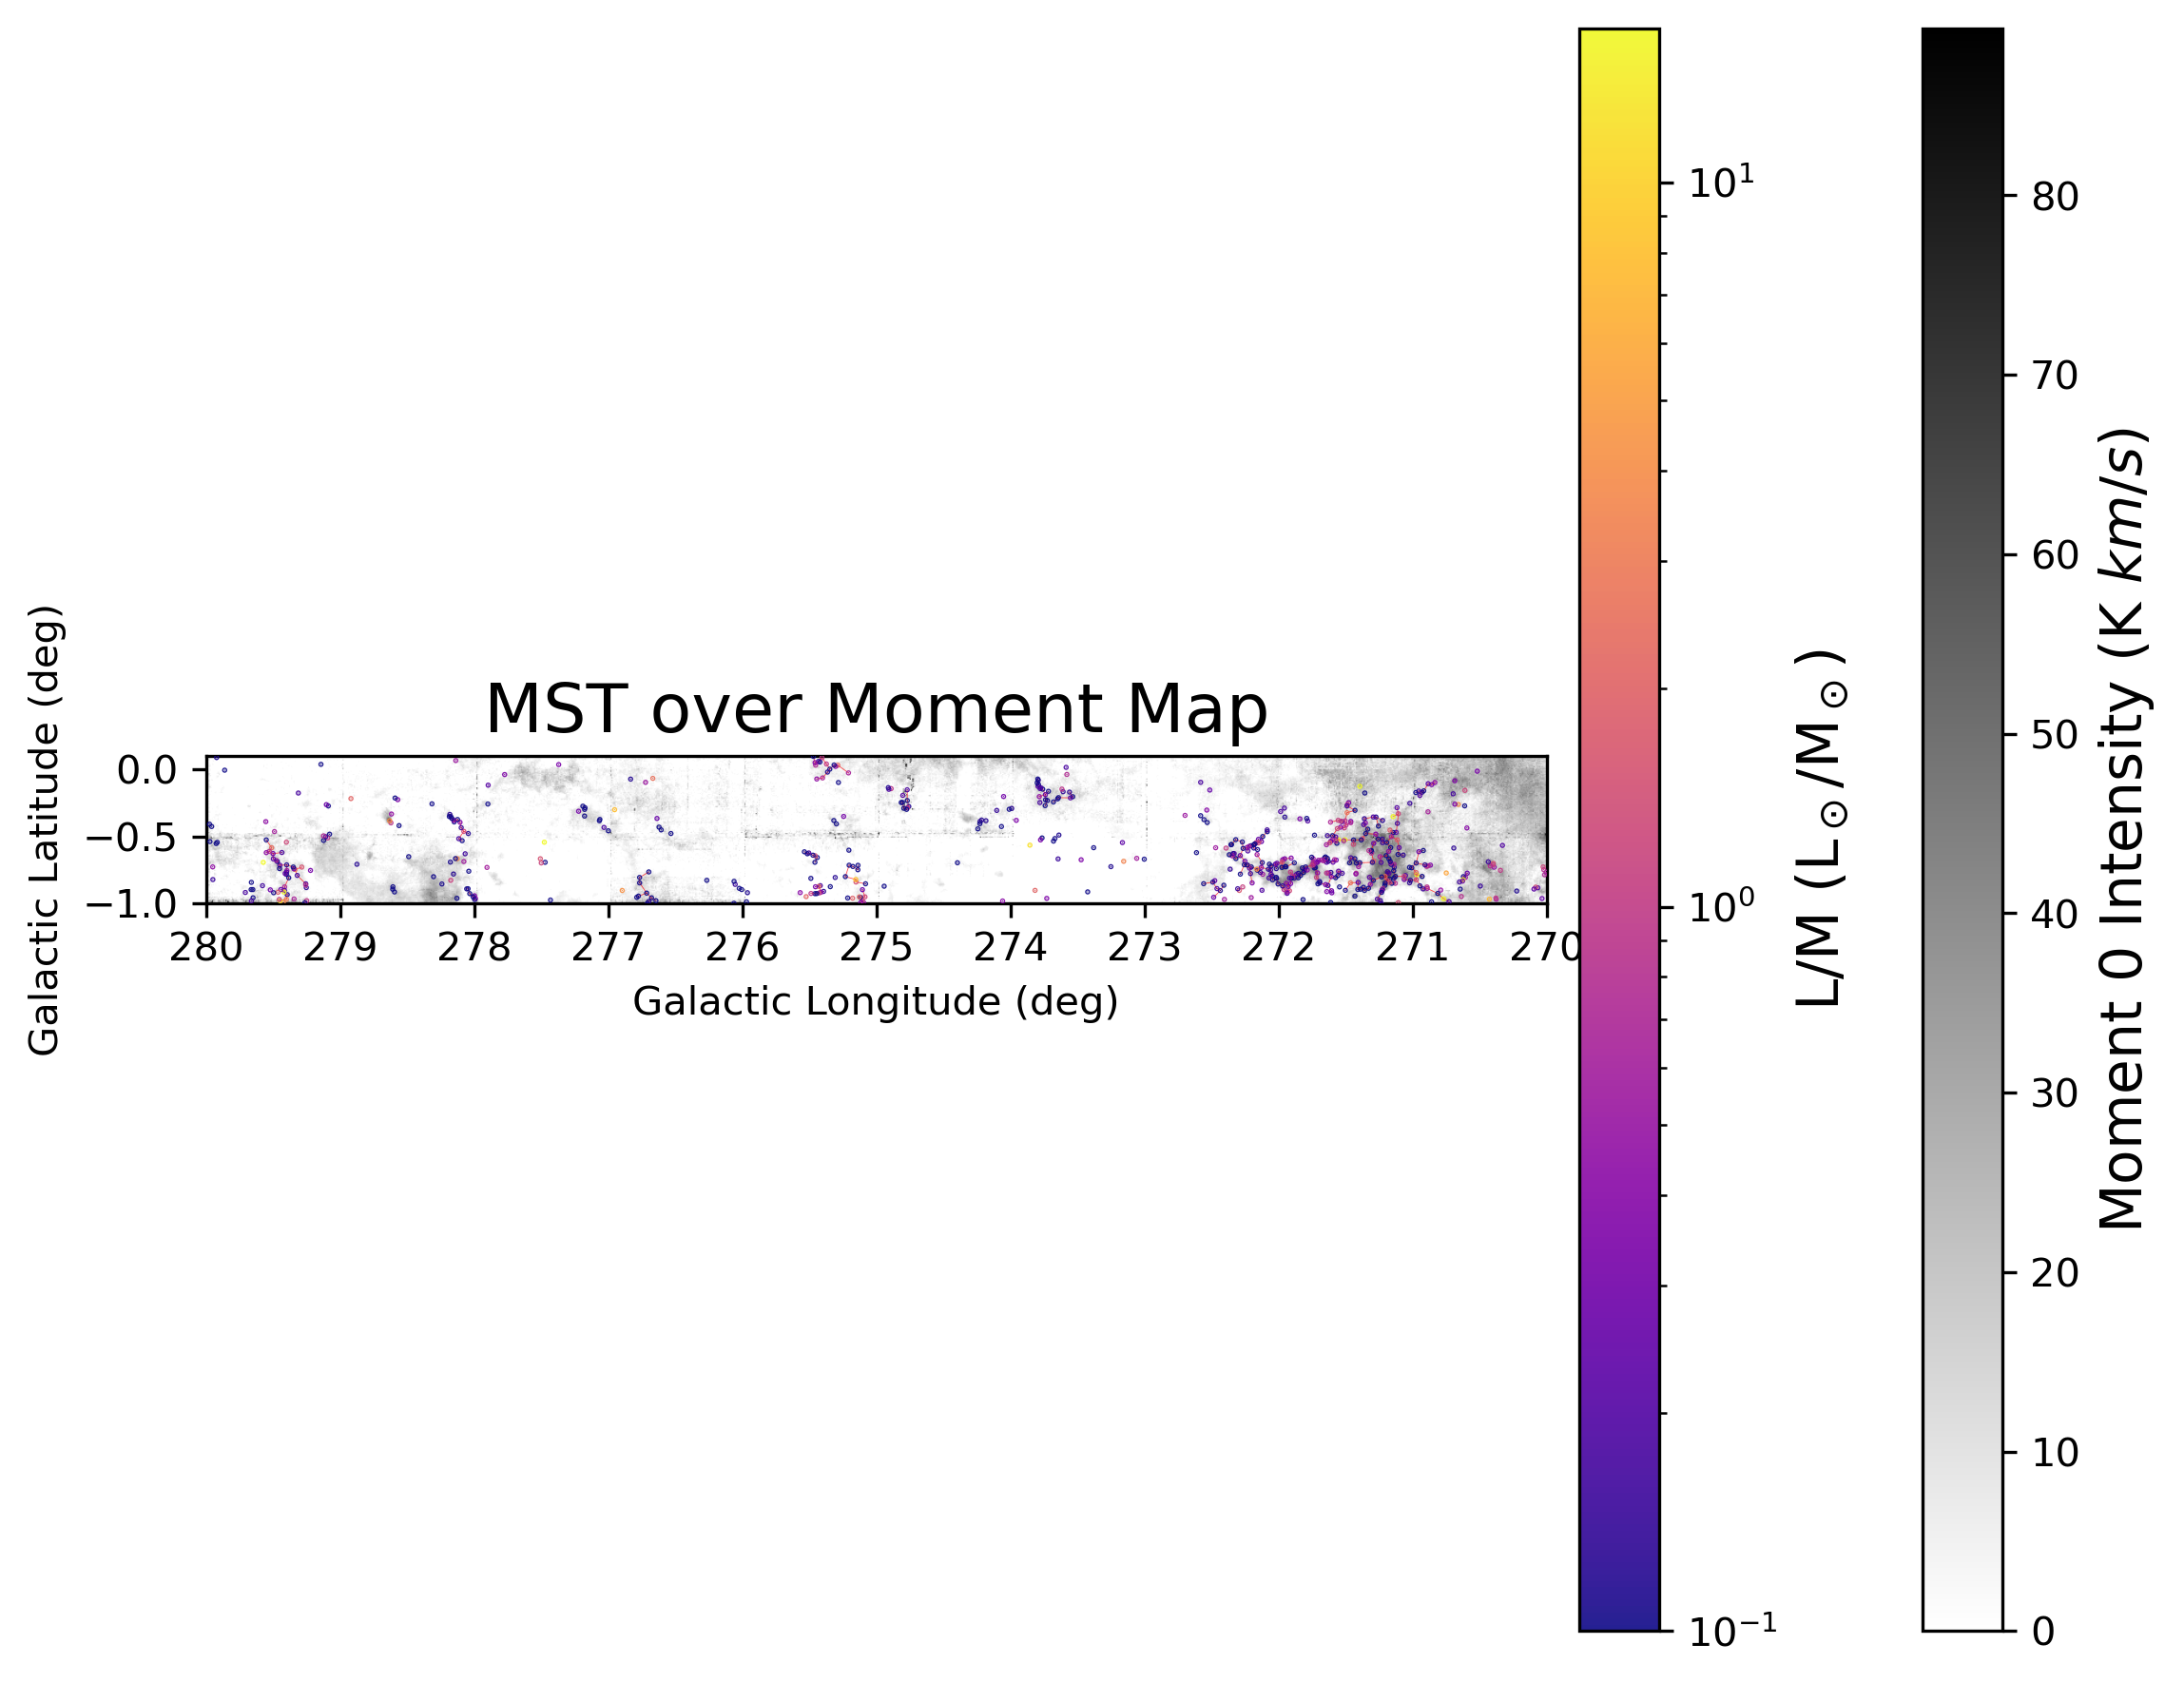

In [12]:
# Succesfully plot logarithmically colour-coded nodes on Moment map
# 4 for Dhc (redundant, all assumed near each other)
# 5 for Rgc ""
# 6 for Mass (Sol)
# 7 for gas2dust
# 8 for diameter (pc)
# 9 for Luminosity (Sol)
# 10 for L / M
# Run fearlessly
import matplotlib.colors as mcolors

csv_filename_enhanced = 'mopra_higal_lbv_results_enhanced.csv'
#filename = "G250-260-12CO_giantcube_fullres_V25_V45_G252.50_G255.00_b-1.00_b0.10.st.mom0.fits" # Original region
#filename = 'G250-260-12CO_giantcube_fullres_V25_V45_G253.35_G253.80_b-0.30_b-0.10.st.mom0.fits' # Ring region
#filename = 'G250-260-12CO_giantcube_fullres_V0_V40_G250.00_G260.00_b-1.00_b0.10.st.mom0.fits' # Full 250-260
#filename = 'G260-270-12CO_giantcube_fullres_V-8_V23_G260.00_G270.00_b-1.00_b0.10.st.mom0.fits' # Full 260-270
filename = 'G270-280-12CO_giantcube_fullres_V-13_V14_G270.00_G280.00_b-1.00_b0.10.st.mom0.fits' # Full 270-280
file_path = "/Users/kyriakos.trakakis/Downloads/MST/Moments_MST/"
fits_file = file_path + filename

# --- Load FITS moment map ---
hdu = fits.open(fits_file)[0]
data = hdu.data
header = hdu.header

l1, l2 =lmin, lmax

# --- Load lbv + column for colouring (example: Mass, col=6) ---
lbv, color_vals, df = get_lbv_enhanced(l1, l2, bmin, bmax, my_dV=1, color_col=10)

# --- Load branch_list from MST analysis ---
with open("branch_list.dat", 'rb') as f:
    branch_list = pickle.load(f)

# --- Plot the moment map ---
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
img = ax.imshow(data, origin="lower", cmap="gray_r",
                extent=[l2, l1, bmin, bmax])

cbar = plt.colorbar(img, ax=ax, pad=0.05)
cbar.set_label("Moment 0 Intensity (K $km/s$)", fontsize="x-large")

plt.xlim(l2, l1)
plt.ylim(bmin, bmax)
ax.xaxis.set_major_locator(MultipleLocator(1)) # set to 1 to display every 1 degree instead of 0.5
ax.yaxis.set_major_locator(MultipleLocator(0.5)) # Set to 0.5 for larger regions and 0.1 for small ones
plt.xlabel("Galactic Longitude (deg)")
plt.ylabel("Galactic Latitude (deg)")
plt.title("MST over Moment Map", fontsize="xx-large")
plt.tight_layout()

# --- Scatter clumps colour-coded by chosen column (logarithmic) ---
# clip to avoid log(0)
color_vals_clipped = np.clip(color_vals, 1e-3, None)

#vmin = color_vals_clipped.min() * 2
vmin = 0.1
#vmax = color_vals_clipped.max() / 2
vmax = 16.331

sc = plt.scatter(lbv[:,0], lbv[:,1], c=color_vals_clipped, cmap="plasma",
                 norm=mcolors.LogNorm(vmin=vmin,
                                      vmax=vmax),
                 s=0.1, zorder=5, alpha=0.9) # s was 12 for small files and 0.1 for big ones

cb2 = plt.colorbar(sc, ax=ax, pad=0.02)
cb2.set_label("L/M (L$_\odot$/M$_\odot$)", fontsize="x-large")  # adjust label per column

# --- Plot MST edges (in red) ---
for branch in branch_list:
    for edge in branch:
        i, j = edge
        l1, b1 = lbv[i, 0], lbv[i, 1]
        l2, b2 = lbv[j, 0], lbv[j, 1]
        plt.plot([l1, l2], [b1, b2], c='r', lw=0.2, alpha=0.7) # lw was 1 for small files and 0.2 for big ones
#plt.savefig('MST_over_Moment_ring_Mass_colourcoded.png')
plt.show()

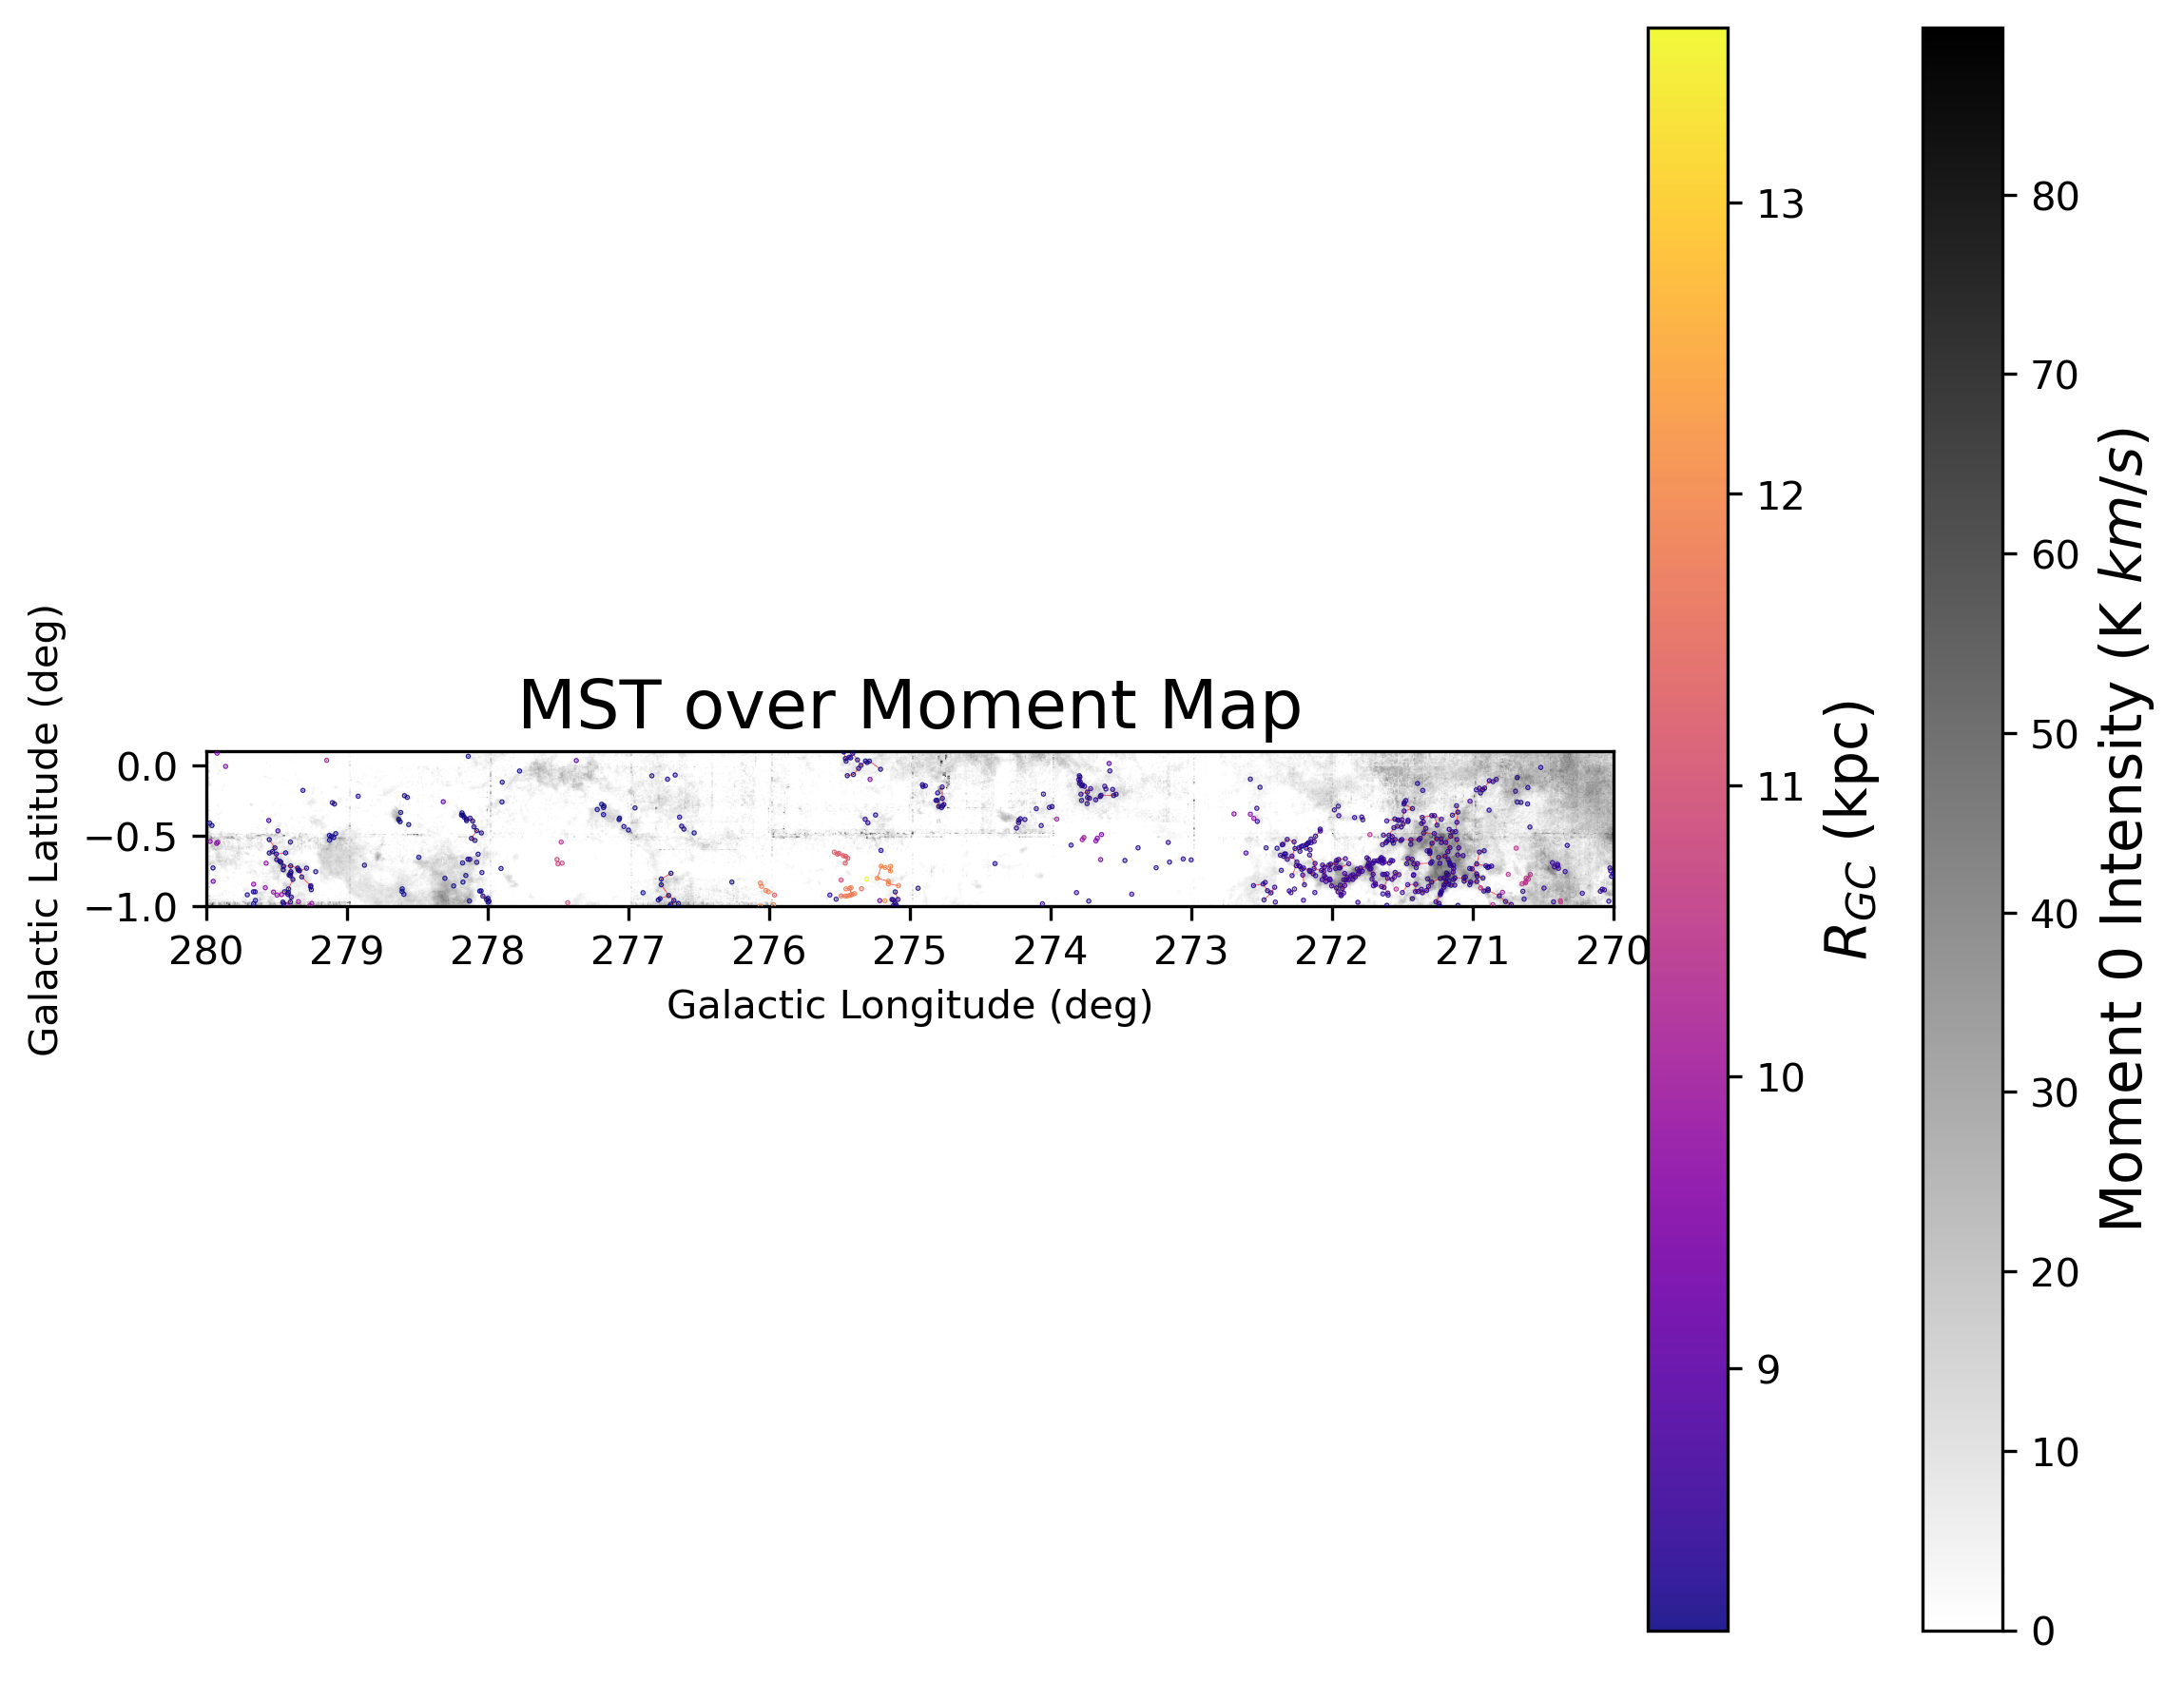

In [13]:
# Succesfully plot NON-logarithmically colour-coded nodes on Moment map
# 4 for Dhc (redundant, all assumed near each other)
# 5 for Rgc ""
# 6 for Mass (Sol)
# 7 for gas2dust
# 8 for diameter (pc)
# 9 for Luminosity (Sol)
# 10 for L / M
# Run fearlessly

# --- Load the FITS moment map ---
#filename = "G250-260-12CO_giantcube_fullres_V25_V45_G252.50_G255.00_b-1.00_b0.10.st.mom0.fits" # Original region
#filename = 'G250-260-12CO_giantcube_fullres_V25_V45_G253.35_G253.80_b-0.30_b-0.10.st.mom0.fits' # Ring region
#filename = 'G250-260-12CO_giantcube_fullres_V0_V40_G250.00_G260.00_b-1.00_b0.10.st.mom0.fits' # Full 250-260
#filename = 'G260-270-12CO_giantcube_fullres_V-8_V23_G260.00_G270.00_b-1.00_b0.10.st.mom0.fits' # Full 260-270
filename = 'G270-280-12CO_giantcube_fullres_V-13_V14_G270.00_G280.00_b-1.00_b0.10.st.mom0.fits' # Full 270-280
file_path = "/Users/kyriakos.trakakis/Downloads/MST/Moments_MST/"
fits_file = file_path + filename
hdu = fits.open(fits_file)[0]
data = hdu.data
header = hdu.header

# Define longitude and latitude range
l1, l2 = lmin, lmax
bmin, bmax = bmin, bmax

# --- Reload lbv + Mass from CSV ---
# Here I assume Mass is column 5 (0-based index 5). Adjust if different.
lbv, color_vals, df = get_lbv_enhanced(l1, l2, bmin, bmax, my_dV=my_dV, color_col=5)

# --- Load branch_list from MST analysis ---
with open("branch_list.dat", 'rb') as f:
    branch_list = pickle.load(f)

# --- Plot the moment map ---
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
img = ax.imshow(data, origin="lower", cmap="gray_r",
                extent=[l2, l1, bmin, bmax])

cbar = plt.colorbar(img, ax=ax, pad=0.01)
cbar.set_label("Moment 0 Intensity (K $km/s$)", fontsize="x-large")

plt.xlim(l2, l1)
plt.ylim(bmin, bmax)
ax.xaxis.set_major_locator(MultipleLocator(1)) # set to 1 to display every 1 degree instead of 0.5
ax.yaxis.set_major_locator(MultipleLocator(0.5))
plt.xlabel("Galactic Longitude (deg)")
plt.ylabel("Galactic Latitude (deg)")
plt.title("MST over Moment Map", fontsize="xx-large")
plt.tight_layout()

# --- Plot clump positions, colour-coded by Mass ---
sc = plt.scatter(lbv[:,0], lbv[:,1], c=color_vals, cmap="plasma",
                 s=0.1, zorder=5, alpha=0.9) # s was 12 for small files and 0.1 for big ones
cb2 = plt.colorbar(sc, ax=ax, pad=0.02)
cb2.set_label("$R_{GC}$ (kpc)", fontsize="x-large")

# --- Plot MST edges (in red) ---
for branch in branch_list:
    for edge in branch:
        i, j = edge
        l1, b1 = lbv[i, 0], lbv[i, 1]
        l2, b2 = lbv[j, 0], lbv[j, 1]
        plt.plot([l1, l2], [b1, b2], c='r', lw=0.2, alpha=0.7) # lw was 1 for small files and 0.2 for big ones
#plt.savefig('MST_over_Moment_ring_Rgc_colourcoded.png')
plt.show()


In [14]:
lbv.shape

(1494, 3)

In [15]:
color_vals.sum()

12852.1

In [16]:
l1

265.402222

# Extracting the different trees

In [14]:
branch_list

[[[23, 26], [26, 27], [27, 28], [28, 31], [26, 21]],
 [[37, 39],
  [39, 41],
  [41, 49],
  [49, 50],
  [49, 55],
  [55, 63],
  [63, 62],
  [62, 65],
  [62, 56],
  [63, 68],
  [68, 70],
  [68, 73],
  [73, 74],
  [74, 72],
  [65, 67],
  [67, 71],
  [67, 64],
  [74, 84],
  [84, 87],
  [87, 85],
  [85, 92],
  [92, 100],
  [100, 105],
  [105, 99],
  [105, 108],
  [108, 110],
  [110, 111],
  [111, 115],
  [115, 116],
  [116, 118],
  [105, 109],
  [109, 101],
  [101, 104],
  [109, 117],
  [84, 89],
  [89, 86],
  [86, 88],
  [88, 94],
  [94, 96],
  [96, 97],
  [97, 102],
  [102, 107],
  [107, 103],
  [103, 95],
  [107, 122],
  [122, 120],
  [95, 106],
  [106, 112],
  [112, 114],
  [114, 124],
  [124, 127],
  [124, 128],
  [128, 135],
  [135, 133],
  [133, 134],
  [135, 138],
  [106, 93],
  [93, 90],
  [90, 98],
  [90, 83],
  [93, 81],
  [118, 125],
  [125, 121],
  [121, 119],
  [81, 76],
  [76, 79],
  [79, 75],
  [64, 52],
  [52, 51],
  [51, 48],
  [48, 45],
  [83, 80],
  [117, 131],
  [131, 1

In [15]:
clump_index = np.unique(np.array(branch))
clump_index

array([583, 584, 585, 587, 589, 590, 592, 593, 594, 595, 596, 597, 598,
       599, 601, 602, 603, 604, 605, 607, 608, 609, 610, 611, 612, 614,
       615, 618, 619, 620, 622, 623, 624])

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def plot_lm_histogram(branch_list, color_vals, savefig=False):
    """
    branch_list : list of MST branches (each branch = list of edges)
    color_vals  : array of L/M values per clump (same order as original data)
    savefig     : if True, saves the histogram
    """
    tree_stats = []

    for branch in branch_list:
        if len(branch) > 1:
            clump_index = np.unique(np.array(branch))  # unique nodes in branch
            total_lm = np.sum(color_vals[clump_index])
            mean_lm = np.mean(color_vals[clump_index])
            tree_stats.append({"n_clumps": len(clump_index),
                               "total_lm": total_lm,
                               "mean_lm": mean_lm})

    tree_df = pd.DataFrame(tree_stats)

    # --- Plot histogram ---
    plt.figure(figsize=(6, 4), dpi=250)
    plt.hist(tree_df["total_lm"], bins=20, color="orange", alpha=0.8,edgecolor='k')
    plt.xlabel("Total Mass per Tree (M$_\\odot$)")
    plt.ylabel("Number of MST Trees")
    plt.title("Histogram of Mass per MST Tree")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    
    if savefig:
        plt.savefig("MST_Mass_histogram_full_region.png", dpi=300)

    plt.show()

    return tree_df


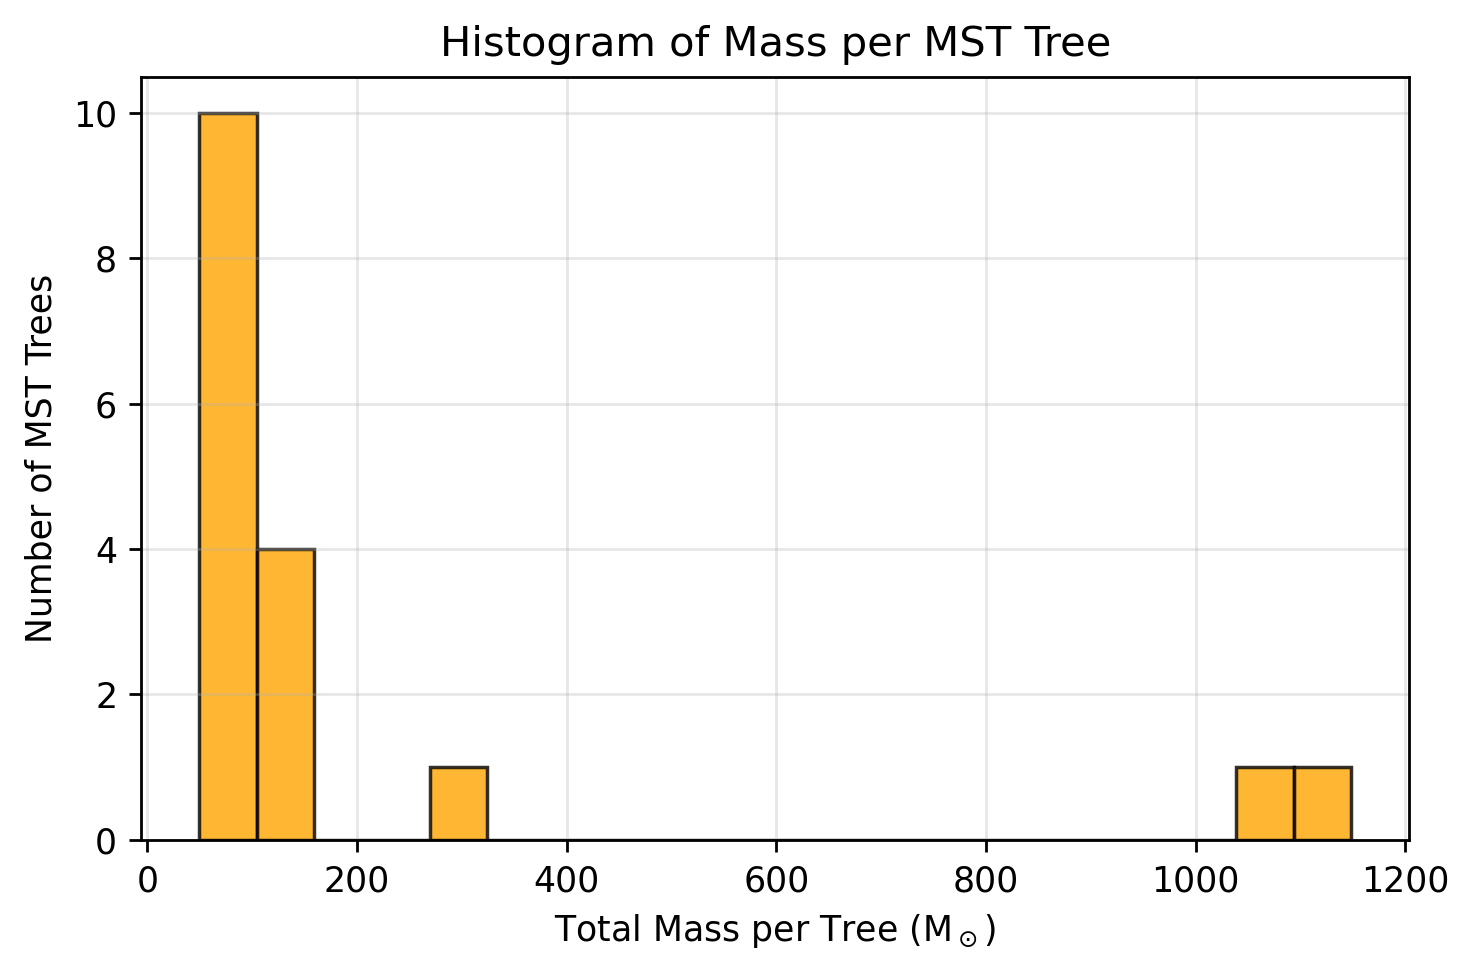

In [17]:
# branch_list = your MST from minimum_spanning_tree
# color_vals = array of L/M values
tree_df = plot_lm_histogram(branch_list, color_vals)


In [18]:
tree_sizes = [len(np.unique(np.array(branch))) for branch in branch_list]
print("Clumps per tree:", tree_sizes)

Clumps per tree: [6, 138, 125, 7, 8, 6, 14, 8, 15, 8, 7, 9, 7, 10, 13, 7, 33]


In [19]:
tree_df

,n_clumps,total_lm,mean_lm
0,6,62.3,10.383333
1,138,1148.5,8.322464
2,125,1054.1,8.432800
3,7,57.9,8.271429
4,8,66.4,8.300000
5,6,49.2,8.200000
6,14,116.2,8.300000
7,8,65.6,8.200000
8,15,122.5,8.166667
9,8,96.0,12.000000


In [20]:
with open("branch_list.dat", "rb") as f:
    branch_list = pickle.load(f)

# Coordinates and colour values
P = lbv[:, 0:2]   # l, b
l = lbv[:, 0]
b = lbv[:, 1]

print(f"Number of trees: {len(branch_list)}")

tree_coords = []
tree_frames = []

for idx, branch in enumerate(branch_list, start=1):
    if len(branch) > 1:

        # Unique point indices in this tree
        clump_index = np.unique(np.array(branch))

        # Coordinates
        coords = P[clump_index]

        # Color values
        cvals = color_vals[clump_index]

        # Full dataframe for this tree
        df_tree = df.iloc[clump_index].reset_index(drop=True)
        tree_frames.append(df_tree)

        print(f"\nTree {idx} has {len(coords)} points:")
        for i, ((l_val, b_val), c) in enumerate(zip(coords, cvals), start=1):
            print(f" Point {i}: l={l_val:.3f}, b={b_val:.3f}, color={c:.3f}")

Number of trees: 17

Tree 1 has 6 points:
 Point 1: l=270.592, b=-0.774, color=10.300
 Point 2: l=270.606, b=-0.807, color=10.400
 Point 3: l=270.621, b=-0.800, color=10.400
 Point 4: l=270.624, b=-0.824, color=10.400
 Point 5: l=270.627, b=-0.834, color=10.400
 Point 6: l=270.650, b=-0.840, color=10.400

Tree 2 has 138 points:
 Point 1: l=270.728, b=-0.987, color=8.300
 Point 2: l=270.768, b=-0.966, color=8.300
 Point 3: l=270.812, b=-0.926, color=8.300
 Point 4: l=270.867, b=-0.715, color=8.400
 Point 5: l=270.885, b=-0.720, color=8.400
 Point 6: l=270.891, b=-0.888, color=8.300
 Point 7: l=270.892, b=-0.877, color=8.300
 Point 8: l=270.895, b=-0.724, color=8.300
 Point 9: l=270.908, b=-0.713, color=8.300
 Point 10: l=270.920, b=-0.606, color=8.200
 Point 11: l=270.922, b=-0.892, color=8.200
 Point 12: l=270.929, b=-0.799, color=8.200
 Point 13: l=270.953, b=-0.614, color=8.300
 Point 14: l=270.969, b=-0.787, color=8.200
 Point 15: l=270.973, b=-0.824, color=8.300
 Point 16: l=270.97

In [28]:
tree_frames[15]

,ï»¿higal_name,gal_long,gal_lat,mopra_vlsr,mopra_dist_kpc,mopra_rgc_kpc,Mass,gas2dust_ratio,mopra_diam_pc,Luminosity,L/M,volume density 2
0,HIGALBM259.8598-0.2621,259.859802,-0.26206,8.78,1.3,8.5,1.156112244889495,150.0,0.19,0.9931160483613025,0.8570378419368987,13786.936058902473
1,HIGALBM259.8613-0.2345,259.861328,-0.234502,8.64,1.2,8.5,14.962354918140317,150.0,0.2,1.3031667847121482,0.08689604502761097,151349.9257745717
2,HIGALBM259.8898-0.1577,259.889771,-0.157678,9.16,1.3,8.5,13.803842191347616,150.6,0.22,2.1428906022964607,0.15523869554154932,96578.18545200158
3,HIGALBM259.9338-0.1165,259.933777,-0.116505,8.29,1.2,8.4,5.7809607977670705,149.7,0.17,1.8281001930602017,0.31622776601683794,92453.57333796755
4,HIGALBM259.9505-0.2506,259.950531,-0.250577,8.53,1.2,8.5,3.845917630433987,150.0,0.19,0.6412095711289968,0.16672472235344687,45956.45352967491
5,HIGALBM259.9638-0.1134,259.963837,-0.113356,8.21,1.2,8.4,2.2387211078430638,149.4,0.15,2.9991625058158315,1.339676699928661,54330.74420196038
6,HIGALBM259.9672-0.2234,259.967163,-0.2234,8.97,1.3,8.5,2.4322040504659173,150.3,0.11,0.693425814962461,0.28510181579434574,134944.86132432905
7,HIGALBM259.9880-0.1121,259.988037,-0.112109,8.3,1.2,8.4,2.009092826947077,149.7,0.16,2.5822601934698097,1.2852866521820654,34563.082344643946
8,HIGALBM259.9921-0.1325,259.992096,-0.132483,8.39,1.2,8.4,2.673006323552688,149.7,0.18,1.8923436622769714,0.7079457746679526,35573.69869235815


In [24]:
pd.to_numeric(tree_frames[0]['Luminosity']).sum()

78.69432481713127

In [25]:
mass_sums = [pd.to_numeric(df['Mass'], errors='coerce').sum() for df in tree_frames]

# Or mean instead
mass_means = [pd.to_numeric(df['Mass'], errors='coerce').mean() for df in tree_frames]

luminosity_sums = [pd.to_numeric(df['Luminosity'], errors='coerce').sum() for df in tree_frames]

print("Mass sums per tree:", mass_sums)
print("Mass means per tree:", mass_means)
print("Luminosity sums per tree:", luminosity_sums)

Mass sums per tree: [1073.5967114790546, 11879.254320425855, 12648.675063302147, 2310.8841980276643, 125.39216234447338, 615.6387436116353, 258.3012456049613, 1615.1856419067144, 10452.734345344112, 86.30155434473764, 2852.3626315482416, 1651.3720276779638, 342.3047531406521, 321.647901112104, 2025.641707371737, 129.78763626853265, 101.2646118371266, 2224.6375374685595, 56.73577642242313, 6602.811364014156, 240.07996007503593, 104.79035265768388, 1473.6285079770792, 96.73435642583726, 187.78576227137623, 146.83096371993207, 99.37479565887597, 3310.9779621192974, 1203.2151769488237, 606.1294038196645, 124.76540283032573, 46.91081675946677, 341.5822215745218, 771.4039551819997, 164.52109595093808, 114.06871194569665, 206.10409848609345, 12427.672655766628, 1537.125416819976, 5460.605294171608, 2025.496164746021, 116.21216644650207, 163.6491558044655, 293.8831326223894, 369.2096469691015, 490.3215775141925, 57.50491562745417, 394.726942529653, 370.1520884460722, 232.53052015127986, 99.170

In [26]:
mass_sums = np.array(mass_sums, dtype=float)
lum_sums  = np.array(luminosity_sums, dtype=float)
l_m = lum_sums/mass_sums
l_m

array([0.07329971, 0.35683838, 0.38318947, 0.15570479, 0.08710408,
       0.59487839, 0.12586117, 0.26338353, 0.0719592 , 0.09337428,
       0.05583112, 0.04309872, 0.02459821, 0.24382234, 0.04224444,
       0.27696878, 0.10113448, 0.03860704, 0.11575714, 0.18446252,
       0.10990423, 0.09500679, 0.87796855, 0.07507902, 0.15218748,
       0.09596147, 0.15588241, 0.16547319, 2.62644351, 1.3489291 ,
       0.07041262, 0.18443586, 0.20013728, 0.09183285, 0.05450855,
       2.8351775 , 0.03622151, 0.54300107, 0.12058432, 0.20576433,
       0.17339003, 0.15041084, 0.12455368, 0.16397591, 0.38004915,
       0.08081929, 1.8173856 , 0.10339011, 0.06143845, 0.1059235 ,
       0.5830678 , 2.28813408, 0.18733956, 0.11931415, 0.10712409,
       0.10926318, 0.1298481 , 0.05530858, 0.05380681, 0.0434614 ,
       0.06990476, 0.12431895, 0.64317853, 0.39707095, 0.1507606 ,
       0.34343716, 0.05190059, 0.09749909, 0.1032332 , 0.2171362 ])

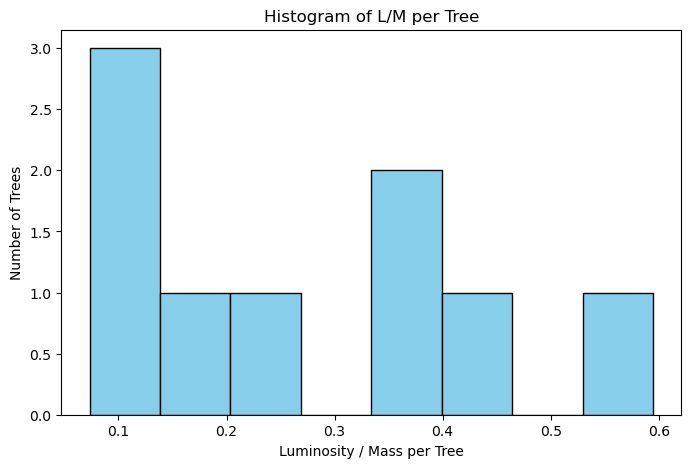

In [158]:
l_m = np.append(l_m, 3792/8368)

plt.figure(figsize=(8,5))
plt.hist(l_m, bins=8, color='skyblue', edgecolor='k')
plt.xlabel('Luminosity / Mass per Tree')
plt.ylabel('Number of Trees')
plt.title('Histogram of L/M per Tree')
plt.show()

l_m = np.delete(l_m, 8)

In [137]:
3792/8368

0.45315487571701724

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_63305/1546130964.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  bin_index = int(bin_index)


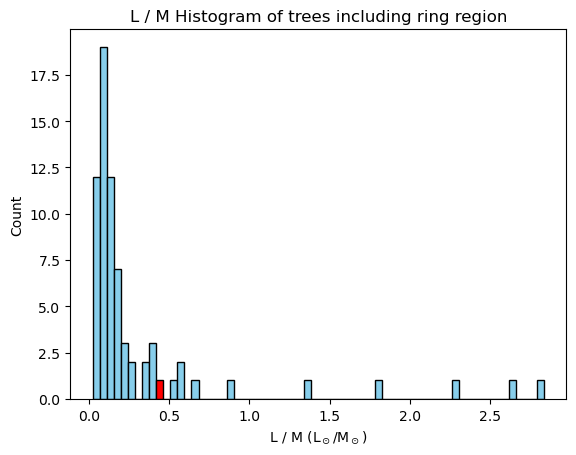

In [28]:
def plot_hist_with_highlight(values, highlight_index, bins=64,
                             remove_after=True, color='skyblue'):
    """
    Plot a histogram where the bar corresponding to values[highlight_index]
    is highlighted in red.

    parameters:
        values          : array-like, input data
        highlight_index : index of the value to highlight
        bins            : number of histogram bins
        remove_after    : if True, removes the highlighted value from the array
        color           : base color of histogram bars

    returns:
        updated array (if remove_after=True)
    """

    # Copy to avoid modifying original array
    arr = np.array(values, dtype=float)

    # Value to highlight
    hv = arr[highlight_index]

    # Create histogram but capture bins + patches
    counts, bin_edges, patches = plt.hist(arr, bins=bins,
                                          color=color, edgecolor='k')

    # Identify which bin contains the highlighted value
    bin_index = np.digitize([hv], bin_edges) - 1
    bin_index = int(bin_index)

    # Highlight that bin
    if 0 <= bin_index < len(patches):
        patches[bin_index].set_facecolor('red')
        patches[bin_index].set_edgecolor('black')

    # Labels
    plt.xlabel('L / M (L$_\odot$/M$_\odot$)')
    plt.ylabel('Count')
    plt.title('L / M Histogram of trees including ring region')

    plt.show()

    # Remove the highlighted point if requested
    if remove_after:
        arr = np.delete(arr, highlight_index)
        return arr
    else:
        return arr

# Add temporary value
l_m = np.append(l_m, 3792/8368)

# Highlight it
l_m = plot_hist_with_highlight(l_m, highlight_index=70)


In [165]:
l_m

array([0.07329971, 0.35683838, 0.38318947, 0.15570479, 0.08710408,
       0.59487839, 0.12586117, 0.26338353])

In [11]:
lbv, color_vals, df = get_lbv_enhanced(l1, l2, bmin, bmax, my_dV=1, color_col=10)
with open("branch_list.dat", 'rb') as f:
    branch_list = pickle.load(f)

In [30]:
l_m.max

2.8351774972875137

In [21]:
dfs_tagged = []

for i, df in enumerate(tree_frames):
    df_copy = df.copy()
    df_copy["tree_index"] = i    # Add column
    dfs_tagged.append(df_copy)

big_df = pd.concat(dfs_tagged, ignore_index=True)

In [22]:
total_sum = 0
for i in range(0,16):
    total_sum += len(tree_frames[i])

print(total_sum)

388


In [23]:
big_df.to_csv("G270-280_MST_sources.csv", index= False)